# Iterative Label Cleaning on MNIST (Train & Test Sets) with `CleanLearning` and Random Forest

This tutorial demonstrates how to use `cleanlab`'s `CleanLearning` wrapper with a `RandomForestClassifier` to iteratively detect and remove all label issues from **both** the published MNIST training set and test set without introducing evaluation bias, evaluate per-class precision/recall/F1 metrics before and after cleaning, visualize common label-noise swaps, export the cleaned CSV datasets and audit logs, and save the trained model with `joblib`.

### 1. Setup & Imports
Install `cleanlab`, `scikit-learn`, and `joblib` if needed (`!pip install cleanlab scikit-learn pandas numpy matplotlib joblib`), then import the required libraries.

In [1]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from cleanlab.classification import CleanLearning
from icecream import ic

# Set a random seed for reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

### 2. Load the Published MNIST CSV Datasets
Load the training (60,000 rows) and test (10,000 rows) CSV files directly from the provided URLs. Column `0` contains the digit label, and columns `1` through `784` contain pixel values (`0` to `255`).

In [13]:
# Original URLS: (Coould not be dowloaded by read_csv, so I downloaded manually)
# train_url = "https://data.pjreddie.com/files/mnist_train.csv"
# test_url = "https://data.pjreddie.com/files/mnist_test.csv"

print("Loading MNIST CSV datasets...")
train_df = pd.read_csv('../data/mnist_train.csv', header=None)
test_df = pd.read_csv('../data/mnist_test.csv', header=None)

# Separate labels (column 0) and features (columns 1 to 784)
# Normalize pixel values to [0, 1]
y_train = train_df.iloc[:, 0].values
X_train = train_df.iloc[:, 1:].values / 255.0

y_test = test_df.iloc[:, 0].values
X_test = test_df.iloc[:, 1:].values / 255.0

print(f"Training data shape: {X_train.shape}, Labels shape: {y_train.shape}")
print(f"Test data shape:     {X_test.shape}, Labels shape: {y_test.shape}")

Loading MNIST CSV datasets...
Training data shape: (60000, 784), Labels shape: (60000,)
Test data shape:     (10000, 784), Labels shape: (10000,)


### 3. Train a Baseline Random Forest Model
Train a standard `RandomForestClassifier` on the raw training data to establish a baseline accuracy before cleaning either dataset.

In [14]:
baseline_rf = RandomForestClassifier(
    n_estimators=100,
    n_jobs=-1,  # Use all available CPU cores for faster training
    random_state=RANDOM_STATE
)

print("Training baseline Random Forest on raw MNIST training data...")
baseline_rf.fit(X_train, y_train)

baseline_raw_test_acc = accuracy_score(y_test, baseline_rf.predict(X_test))
print(f"Baseline Model Accuracy (Raw Test Set): {baseline_raw_test_acc:.4%}")

Training baseline Random Forest on raw MNIST training data...
Baseline Model Accuracy (Raw Test Set): 97.0400%


### 4. Helper Function for Iterative Cleaning & Audit Logging
Define a reusable function that runs iterative `CleanLearning` passes on any dataset `(X, y)` until zero label issues remain. Alongside pruning noisy samples, it logs each removed row's original index, removal iteration, given label, predicted alternative label, and label quality score.

In [15]:
def iterative_clean_dataset(X, y, dataset_name="Dataset", base_seed=42):
    X_curr = X.copy()
    y_curr = y.copy()
    original_indices = np.arange(len(y))
    
    iteration = 0
    removed_records = []
    stats = []
    
    while True:
        iteration += 1
        print(f"\n[{dataset_name}] Iteration {iteration} (Current samples: {len(y_curr)})")
        
        rf_model = RandomForestClassifier(
            n_estimators=100,
            n_jobs=-1,
            random_state=base_seed + iteration
        )
        cl = CleanLearning(clf=rf_model, cv_n_folds=5, seed=base_seed + iteration)
        cl.fit(X_curr, y_curr)
        
        issues_df = cl.get_label_issues()
        is_issue_mask = issues_df["is_label_issue"].values
        num_issues = int(is_issue_mask.sum())
        
        print(f"[{dataset_name}] Label issues detected: {num_issues}")
        
        stats.append({
            "iteration": iteration,
            "samples_before_pruning": len(y_curr),
            "issues_removed": num_issues
        })
        
        if num_issues == 0:
            print(f"[{dataset_name}] All label issues removed!")
            removed_log_df = pd.DataFrame(removed_records)
            return X_curr, y_curr, cl, removed_log_df, original_indices, pd.DataFrame(stats)
        
        # Record detailed audit metadata for each flagged row
        flagged_issues = issues_df[is_issue_mask]
        flagged_orig_idx = original_indices[is_issue_mask]
        flagged_given_labels = y_curr[is_issue_mask]
        
        for orig_idx, given_lbl, (_, row) in zip(flagged_orig_idx, flagged_given_labels, flagged_issues.iterrows()):
            removed_records.append({
                "dataset": dataset_name,
                "original_index": int(orig_idx),
                "iteration_removed": iteration,
                "given_label": int(given_lbl),
                "predicted_label": int(row["predicted_label"]),
                "label_quality_score": float(row["label_quality"])
            })
        
        keep_mask = ~is_issue_mask
        X_curr = X_curr[keep_mask]
        y_curr = y_curr[keep_mask]
        original_indices = original_indices[keep_mask]

### 5. Iteratively Clean the Training Set and Test Set Independently
Run the iterative cleaning function on `(X_train, y_train)` to obtain `final_clean_model`, and run it separately on `(X_test, y_test)` using internal cross-validation so `X_train` never influences which test samples are pruned.

In [16]:
print("=== Cleaning Training Set ===")
X_train_clean, y_train_clean, final_clean_model, train_removed_log, train_kept_idx, train_stats_df = iterative_clean_dataset(
    X_train, y_train, dataset_name="Train Set", base_seed=RANDOM_STATE
)

print("\n=== Cleaning Test Set Independently ===")
X_test_clean, y_test_clean, _, test_removed_log, test_kept_idx, test_stats_df = iterative_clean_dataset(
    X_test, y_test, dataset_name="Test Set", base_seed=RANDOM_STATE + 100
)

=== Cleaning Training Set ===

[Train Set] Iteration 1 (Current samples: 60000)
[Train Set] Label issues detected: 43

[Train Set] Iteration 2 (Current samples: 59957)
[Train Set] Label issues detected: 10

[Train Set] Iteration 3 (Current samples: 59947)
[Train Set] Label issues detected: 4

[Train Set] Iteration 4 (Current samples: 59943)
[Train Set] Label issues detected: 3

[Train Set] Iteration 5 (Current samples: 59940)
[Train Set] Label issues detected: 0
[Train Set] All label issues removed!

=== Cleaning Test Set Independently ===

[Test Set] Iteration 1 (Current samples: 10000)
[Test Set] Label issues detected: 13

[Test Set] Iteration 2 (Current samples: 9987)
[Test Set] Label issues detected: 2

[Test Set] Iteration 3 (Current samples: 9985)
[Test Set] Label issues detected: 0
[Test Set] All label issues removed!


### 6. Side-by-Side Accuracy & Cleaning Comparison
Compare the baseline Random Forest model against the clean-trained Random Forest model across both the raw test set and the cleaned test set.

In [17]:
# Evaluate both models on both test sets
baseline_clean_test_acc = accuracy_score(y_test_clean, baseline_rf.predict(X_test_clean))
clean_model_raw_test_acc = accuracy_score(y_test, final_clean_model.predict(X_test))
clean_model_clean_test_acc = accuracy_score(y_test_clean, final_clean_model.predict(X_test_clean))

comparison_df = pd.DataFrame([
    {
        "Model": "Baseline RF (Trained on Raw Train)",
        "Raw Test Set Accuracy": f"{baseline_raw_test_acc:.4%}",
        "Clean Test Set Accuracy": f"{baseline_clean_test_acc:.4%}"
    },
    {
        "Model": "CleanLearning RF (Trained on Clean Train)",
        "Raw Test Set Accuracy": f"{clean_model_raw_test_acc:.4%}",
        "Clean Test Set Accuracy": f"{clean_model_clean_test_acc:.4%}"
    }
])

print("=== Dataset Pruning Summary ===")
print(f"Train Set: Removed {len(train_removed_log)} / {len(y_train)} samples ({len(train_removed_log)/len(y_train):.2%})")
print(f"Test Set:  Removed {len(test_removed_log)} / {len(y_test)} samples ({len(test_removed_log)/len(y_test):.2%})")

print("\n=== Side-by-Side Accuracy Comparison ===")
print(comparison_df.to_string(index=False))

=== Dataset Pruning Summary ===
Train Set: Removed 60 / 60000 samples (0.10%)
Test Set:  Removed 15 / 10000 samples (0.15%)

=== Side-by-Side Accuracy Comparison ===
                                    Model Raw Test Set Accuracy Clean Test Set Accuracy
       Baseline RF (Trained on Raw Train)              97.0400%                97.1858%
CleanLearning RF (Trained on Clean Train)              96.9900%                97.1157%


### 7. Per-Class Precision, Recall, and F1-Score Comparison
Generate detailed per-digit classification reports before and after cleaning, along with a side-by-side table showing exact F1-score gains for each digit (`0` through `9`).

In [18]:
digits = list(range(10))
target_names = [f"Digit {d}" for d in digits]

baseline_preds_raw = baseline_rf.predict(X_test)
clean_preds_clean = final_clean_model.predict(X_test_clean)

print("=== Baseline RF on Raw Test Set (Before Cleaning) ===")
print(classification_report(y_test, baseline_preds_raw, target_names=target_names, digits=4))

print("=== CleanLearning RF on Clean Test Set (After Cleaning) ===")
print(classification_report(y_test_clean, clean_preds_clean, target_names=target_names, digits=4))

# Build a concise per-class F1 delta summary table
report_before = classification_report(y_test, baseline_preds_raw, output_dict=True)
report_after = classification_report(y_test_clean, clean_preds_clean, output_dict=True)

f1_comparison_rows = []
for d in digits:
    key = str(d)
    f1_before = report_before[key]["f1-score"]
    f1_after = report_after[key]["f1-score"]
    f1_comparison_rows.append({
        "Digit": d,
        "Precision (Before)": f"{report_before[key]['precision']:.4f}",
        "Recall (Before)": f"{report_before[key]['recall']:.4f}",
        "F1 (Before)": f"{f1_before:.4f}",
        "Precision (After)": f"{report_after[key]['precision']:.4f}",
        "Recall (After)": f"{report_after[key]['recall']:.4f}",
        "F1 (After)": f"{f1_after:.4f}",
        "F1 Delta": f"{f1_after - f1_before:+.4f}"
    })

f1_comparison_df = pd.DataFrame(f1_comparison_rows)
print("=== Per-Class Metric Shifts (Before vs. After Cleaning) ===")
print(f1_comparison_df.to_string(index=False))

=== Baseline RF on Raw Test Set (Before Cleaning) ===
              precision    recall  f1-score   support

     Digit 0     0.9681    0.9908    0.9793       980
     Digit 1     0.9877    0.9930    0.9903      1135
     Digit 2     0.9616    0.9709    0.9662      1032
     Digit 3     0.9633    0.9624    0.9629      1010
     Digit 4     0.9745    0.9725    0.9735       982
     Digit 5     0.9762    0.9641    0.9701       892
     Digit 6     0.9760    0.9781    0.9771       958
     Digit 7     0.9715    0.9621    0.9668      1028
     Digit 8     0.9617    0.9548    0.9583       974
     Digit 9     0.9620    0.9524    0.9572      1009

    accuracy                         0.9704     10000
   macro avg     0.9703    0.9701    0.9702     10000
weighted avg     0.9704    0.9704    0.9704     10000

=== CleanLearning RF on Clean Test Set (After Cleaning) ===
              precision    recall  f1-score   support

     Digit 0     0.9710    0.9908    0.9808       980
     Digit 1     0

### 8. Visualize Removed Test Set Images
Inspect the first 10 images flagged and removed from the MNIST test set to visually verify the label errors.

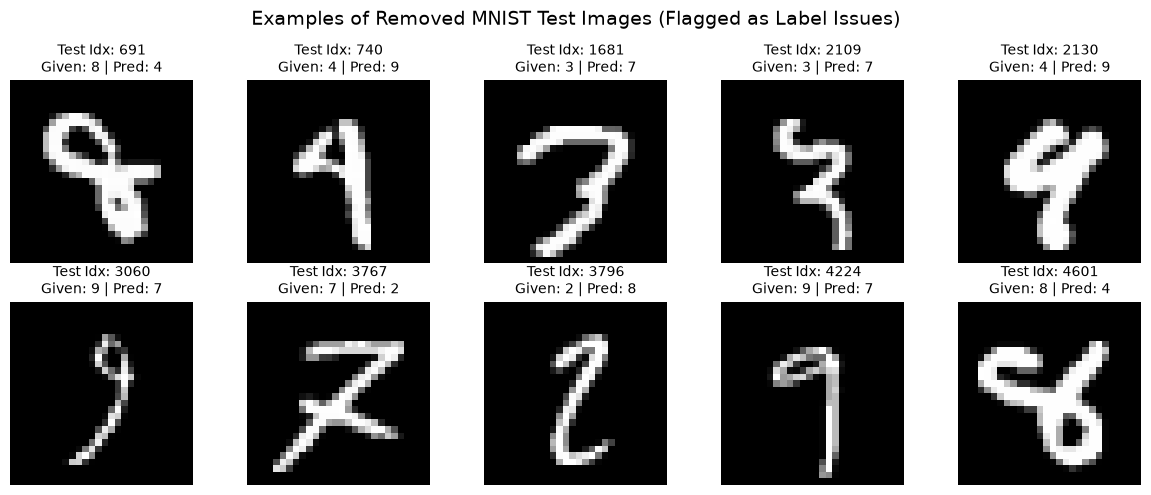

In [19]:
num_to_show = min(10, len(test_removed_log))

if num_to_show > 0:
    fig, axes = plt.subplots(2, 5, figsize=(12, 5))
    fig.suptitle("Examples of Removed MNIST Test Images (Flagged as Label Issues)", fontsize=14)
    
    for i, ax in enumerate(axes.flat):
        if i < num_to_show:
            row_info = test_removed_log.iloc[i]
            orig_idx = int(row_info["original_index"])
            img = X_test[orig_idx].reshape(28, 28)
            given_label = int(row_info["given_label"])
            predicted_label = int(row_info["predicted_label"])
            
            ax.imshow(img, cmap="gray")
            ax.set_title(f"Test Idx: {orig_idx}\nGiven: {given_label} | Pred: {predicted_label}", fontsize=10)
        ax.axis("off")
        
    plt.tight_layout()
    plt.show()
else:
    print("No label issues were removed from the test set.")

### 9. Confusion Matrix of Most Common Label Swaps
Analyze all removed rows across both datasets to see which digit pairs are most frequently mislabeled (e.g., `4` vs. `9`, `3` vs. `8`, or `7` vs. `1`).

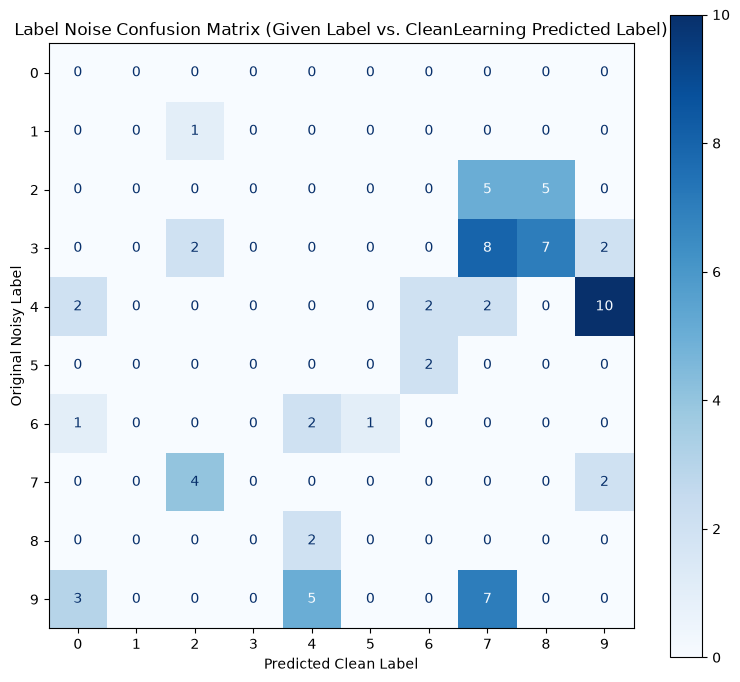

=== Top 10 Most Common Label Swaps ===
 given_label  predicted_label  count
           4                9     10
           3                7      8
           3                8      7
           9                7      7
           2                8      5
           2                7      5
           9                4      5
           7                2      4
           9                0      3
           6                4      2


In [20]:
combined_removed_log = pd.concat([train_removed_log, test_removed_log], ignore_index=True)

if len(combined_removed_log) > 0:
    cm = confusion_matrix(
        combined_removed_log["given_label"],
        combined_removed_log["predicted_label"],
        labels=digits
    )
    
    fig, ax = plt.subplots(figsize=(8, 7))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=digits)
    disp.plot(ax=ax, cmap="Blues", values_format="d")
    ax.set_title("Label Noise Confusion Matrix (Given Label vs. CleanLearning Predicted Label)")
    ax.set_xlabel("Predicted Clean Label")
    ax.set_ylabel("Original Noisy Label")
    plt.tight_layout()
    plt.show()
    
    # Print top 10 most common label swap pairs
    swap_counts = (
        combined_removed_log.groupby(["given_label", "predicted_label"])
        .size()
        .reset_index(name="count")
        .sort_values("count", ascending=False)
    )
    print("=== Top 10 Most Common Label Swaps ===")
    print(swap_counts.head(10).to_string(index=False))
else:
    print("No label swaps to display.")

### 10. Export Cleaned Datasets, Audit Log, and Trained Model
Save all outputs to disk:
1. `mnist_train_clean.csv` & `mnist_test_clean.csv`: Surviving rows in the exact original headerless format (label in column `0`, raw `0–255` pixel values in columns `1–784`).
2. `mnist_removed_rows_log.csv`: Combined audit log detailing every removed row across both datasets.
3. `mnist_clean_rf_model.joblib`: Serialized `CleanLearning` Random Forest model (plus its underlying `clf` estimator) ready for inference.

In [21]:
# 1. Export cleaned datasets in original headerless format
clean_train_df = train_df.iloc[train_kept_idx]
clean_test_df = test_df.iloc[test_kept_idx]

clean_train_df.to_csv("mnist_train_clean.csv", header=False, index=False)
clean_test_df.to_csv("mnist_test_clean.csv", header=False, index=False)

print(f"Exported mnist_train_clean.csv with shape: {clean_train_df.shape}")
print(f"Exported mnist_test_clean.csv with shape:  {clean_test_df.shape}")

# 2. Export combined audit log of all removed rows
combined_removed_log.to_csv("mnist_removed_rows_log.csv", index=False)
print(f"Exported mnist_removed_rows_log.csv with {len(combined_removed_log)} removed rows.")

# 3. Save the trained clean Random Forest model using joblib
model_path = "mnist_clean_rf_model.joblib"
joblib.dump(final_clean_model, model_path, compress=3)
print(f"Saved trained CleanLearning Random Forest model to: {model_path}")

# Quick verification of model reload and inference
loaded_model = joblib.load(model_path)
reloaded_acc = accuracy_score(y_test_clean, loaded_model.predict(X_test_clean))
print(f"Verified reloaded model accuracy on clean test set: {reloaded_acc:.4%}")

Exported mnist_train_clean.csv with shape: (59940, 785)
Exported mnist_test_clean.csv with shape:  (9985, 785)
Exported mnist_removed_rows_log.csv with 75 removed rows.
Saved trained CleanLearning Random Forest model to: mnist_clean_rf_model.joblib
Verified reloaded model accuracy on clean test set: 97.1157%
